# Case: Your Electricity Bill - after Lesson 2

A running example that grows with the course. After each lesson, the case gets a new chapter that uses *exactly* the tools you have just learned - on **real, live data** about electricity prices and the Danish economy.


> ⚠️ **Important**: This is **not** an example of an exam-style task. It is an example of what the course's tools can do once you put them together. The purpose is inspiration and play - not syllabus material beyond what you have already learned.


### How to read the case

* Each chapter belongs to one lesson and only uses tools from the lessons up to and including it.
* Cells marked **Engine room** fetch data from the internet (Energi Data Service and Statistics Denmark). You do not need to understand the code inside them - they just hand over the numbers. If they cannot reach the internet, they automatically fall back to cached numbers, so the notebook always works.
* **You are allowed to change everything!** Change a number and run the cell again with Shift+Enter (or ▶). If later cells use the result, run those again too. If something breaks, just choose *Runtime → Restart session and run all* - and you are back at the start.
* Each chapter ends with **Turn the dials** - concrete suggestions for what you can change. That is where it gets fun.


## Today's electricity price

Electricity is traded on an exchange, hour by hour, the day before. The **spot price** is the raw market price (before taxes, transport, and VAT) - and it swings wildly over the course of a day. Let's fetch the latest available day's prices for western Denmark (DK1) and take a first look with a plot. Once we've covered functions and differentiation in Lesson 5, we will come back and read this curve's slope too.


In [1]:
#@title Engine room: defines the function fetch_electricity_prices(area) (you do not need to understand this cell)
import requests, json
import numpy as np

_CACHED_PRICES = [0.975, 0.959, 0.958, 0.937, 0.936, 0.984, 1.064, 1.1, 1.068, 0.942, 0.756, 0.496, 0.232, 0.125, 0.162, 0.348, 0.641, 0.863, 1.053, 1.273, 1.468, 1.458, 1.334, 1.239]
_CACHED_DATE = "2026-08-07"
_SOURCE_FALLBACK = "cached DK1 prices (fallback)"

def fetch_electricity_prices(area):
    # Fetches the most recent day's spot prices (kr/kWh) for a price area, e.g. "DK1"
    try:
        r = requests.get("https://api.energidataservice.dk/dataset/DayAheadPrices",
                         params={"limit": 200, "sort": "TimeDK desc",
                                 "filter": json.dumps({"PriceArea": [area]})}, timeout=10)
        records = r.json()["records"]
        date = records[0]["TimeDK"][:10]
        by_hour = {}
        for x in records:
            if x["TimeDK"][:10] == date:
                by_hour.setdefault(x["TimeDK"][11:13], []).append(x["DayAheadPriceDKK"])
        prices = [sum(v) / len(v) / 1000 for _, v in sorted(by_hour.items())]
        if len(prices) != 24:
            raise ValueError("incomplete day")
    except Exception:
        # The fallback ALWAYS returns the cached DK1 prices - regardless of which area was requested.
        # That is why the caller gets an honest source label back, so DK2 (or any other area)
        # can never be mistaken for real data for that area in a graph or a calculation.
        print(f"(Could not fetch live data for {area} - showing cached DK1 prices from {_CACHED_DATE} instead)")
        return np.array(_CACHED_PRICES), _CACHED_DATE, _SOURCE_FALLBACK
    print(f"Fetched fresh spot prices for {date} ({area})")
    return np.array(prices), date, f"live {area}"


In [2]:
# Fetch the latest available day's prices for western Denmark - the function comes from the engine room above
electricity_prices, date, source_dk1 = fetch_electricity_prices("DK1")

hours = np.arange(24)


Fetched fresh spot prices for 2026-08-14 (DK1)


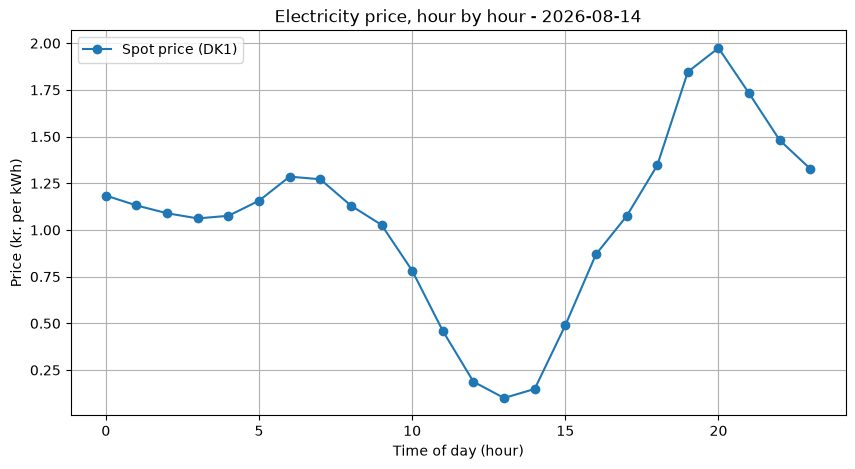

In [3]:
import matplotlib.pyplot as plt

# Plot the daily profile
plt.figure(figsize=(10, 5))
plt.plot(hours, electricity_prices, 'o-', label="Spot price (DK1)")
plt.title(f"Electricity price, hour by hour - {date}")
plt.xlabel("Time of day (hour)")
plt.ylabel("Price (kr. per kWh)")
plt.legend()
plt.grid(True)
plt.show()


Electricity prices follow the rhythm of society - and the seasons. In winter, the morning and evening hours are typically the most expensive. In summer, solar power can push the price right down in the middle of the day - sometimes even below zero. Look at **your** graph: when is electricity cheapest today, and where does the curve rise or fall most steeply?

We will come back to measure that steepness properly once we have covered functions and differentiation, in Chapter 5.


### West versus East - and the rest of the neighbourhood

The electricity market is split into price areas, and the function can fetch any of them - you just give it the name:

* `"DK1"` - Denmark **west** of the Great Belt (Storebælt) - Jutland and Funen, and Aalborg!
* `"DK2"` - Denmark **east** of the Great Belt - Zealand and Copenhagen
* `"NO2"` - southern Norway (hydropower!)
* `"SE3"` and `"SE4"` - central and southern Sweden
* `"DE"` - Germany

In Chapter 5, once we also have the tools to describe a curve's slope, we will fetch DK2 as well and compare the two areas head-to-head.


## Chapter 1 - Fixed or variable electricity agreement? *(after Lesson 1: Linear Equations)*

Two typical agreements (the numbers are illustrative - the spot price is real):

* **Fixed price**: no subscription fee, but 2.35 kr. per kWh - all year round.
* **Variable**: 49 kr. subscription per month + the spot price + a 0.65 kr. surcharge per kWh.

When is which cheaper? These are two linear functions - and the crossing point is a **system of linear equations**, which we solve exactly as in Lesson 1.

The prices here are the supplier's component of the bill - the full electricity bill also has grid tariffs, taxes, and VAT on top.


In [4]:
#@title Engine room: fetches the latest month's average spot price
_CACHED_AVG = 0.834

def fetch_month_average():
    try:
        from datetime import date, timedelta
        end_date = date.today()
        start_date = end_date - timedelta(days=30)
        r = requests.get("https://api.energidataservice.dk/dataset/DayAheadPrices",
                         params={"start": str(start_date), "end": str(end_date), "limit": 3000,
                                 "filter": json.dumps({"PriceArea": ["DK1"]})}, timeout=15)
        records = r.json()["records"]
        average = sum(x["DayAheadPriceDKK"] for x in records) / len(records) / 1000
        print(f"Latest month's average spot price: {average:.2f} kr/kWh")
        return average
    except Exception:
        print(f"(Could not fetch live data - using cached average: {_CACHED_AVG} kr/kWh)")
        return _CACHED_AVG

spot_average = fetch_month_average()


Latest month's average spot price: 0.85 kr/kWh


In [5]:
from sympy import Matrix, linsolve, symbols

# Monthly price as a function of consumption f (kWh):
#   Fixed price: price = 2.35*f          ->  2.35*f - price = 0
#   Variable:    price = 49 + a*f        ->  a*f - price = -49
a = spot_average + 0.65

f, price = symbols('f price')
intersection = linsolve(Matrix(([2.35, -1, 0], [a, -1, -49])), (f, price))
print(f"The agreements cost the same at {list(intersection)[0][0]:.0f} kWh/month ({list(intersection)[0][1]:.0f} kr./month)")

# Same answer with NumPy (Lesson 1)
A_sys = np.array([[2.35, -1], [a, -1]])
b_sys = np.array([0, -49])
np.linalg.solve(A_sys, b_sys)


The agreements cost the same at 57 kWh/month (135 kr./month)


array([ 57.47075311, 135.0562698 ])

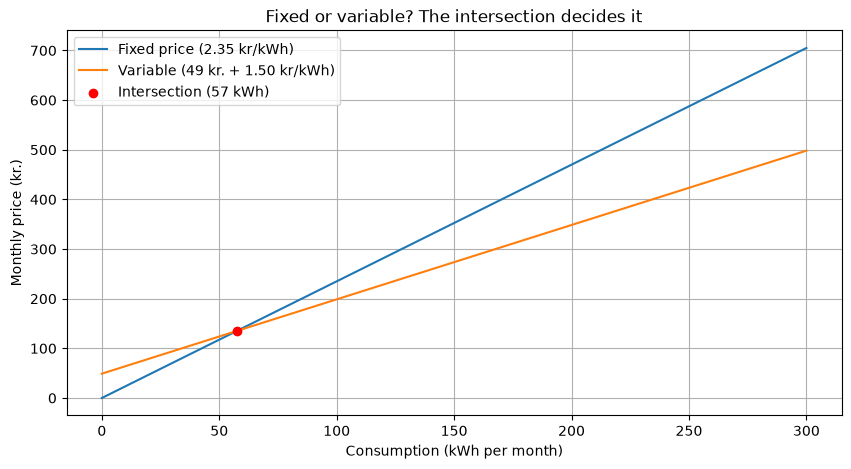

A typical apartment uses 125-175 kWh/month - read off for yourself which agreement wins right now


In [6]:
# Visualise the intersection point
consumption = np.linspace(0, 300, 100)
plt.figure(figsize=(10, 5))
plt.plot(consumption, 2.35 * consumption, label="Fixed price (2.35 kr/kWh)")
plt.plot(consumption, 49 + a * consumption, label=f"Variable (49 kr. + {a:.2f} kr/kWh)")

# The intersection only exists if the variable price per kWh (a) is actually LOWER than the fixed price.
# If a >= 2.35, the variable agreement is more expensive at every consumption level (it also has a
# subscription fee on top) - so the lines never cross for a positive consumption, and x_intersection
# would become meaninglessly negative.
if a >= 2.35:
    print(f"With a = {a:.2f} kr/kWh the variable agreement is more expensive than the fixed price at every consumption level -")
    print("there is no intersection: the fixed-price agreement wins at every consumption level with these prices.")
else:
    x_intersection = 49 / (2.35 - a)
    plt.scatter(x_intersection, 2.35 * x_intersection, color="red", zorder=5, label=f"Intersection ({x_intersection:.0f} kWh)")

plt.title("Fixed or variable? The intersection decides it")
plt.xlabel("Consumption (kWh per month)")
plt.ylabel("Monthly price (kr.)")
plt.legend()
plt.grid(True)
plt.show()

print("A typical apartment uses 125-175 kWh/month - read off for yourself which agreement wins right now")


#### Turn the dials

* **No subscription fee**: Change `49` to `0` in both the calculation cell and the plot cell, and run them again - where does the intersection move to?
* **Back to 2022**: Add the line `spot_average = 2.10` as a new top line in the calculation cell, and run both cells again. Back then, the picture looked completely different.


## Chapter 2 - Your consumption as a vector *(after Lesson 2: Vectors)*

Your daily consumption is a **vector**: 24 numbers, one per hour. Today's electricity prices are also a vector. And your daily bill? It is the **dot product** of the two - exactly as in Lesson 2.


In [7]:
# Two daily profiles (kWh per hour) - RAW shape, normalised below to the same daily consumption
early_bird_raw = np.array([0.1, 0.1, 0.1, 0.1, 0.1, 0.3, 0.8, 0.9, 0.6, 0.3, 0.2, 0.2,
                           0.2, 0.2, 0.2, 0.3, 0.5, 0.8, 0.9, 0.6, 0.4, 0.3, 0.2, 0.1])
night_owl_raw = np.array([0.4, 0.3, 0.2, 0.1, 0.1, 0.1, 0.1, 0.2, 0.3, 0.3, 0.3, 0.3,
                      0.3, 0.3, 0.3, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.8, 0.6])

# Scale both profiles to EXACTLY the same daily consumption, so that only the SHAPE (when the
# electricity is used) distinguishes the two households - not the total amount
daily_consumption = 8.0  # kWh
early_bird = early_bird_raw / np.sum(early_bird_raw) * daily_consumption
night_owl = night_owl_raw / np.sum(night_owl_raw) * daily_consumption

print(f"Early bird: {np.sum(early_bird):.1f} kWh/day - Night owl: {np.sum(night_owl):.1f} kWh/day")


Early bird: 8.0 kWh/day - Night owl: 8.0 kWh/day


In [8]:
# The daily bill = consumption vector . price vector (the dot product from Lesson 2)
cost_early_bird = early_bird @ electricity_prices
cost_night_owl = night_owl @ electricity_prices

print(f"The early bird's day: {cost_early_bird:.2f} kr.")
print(f"The night owl's day: {cost_night_owl:.2f} kr.")
print(f"Difference: {abs(cost_early_bird - cost_night_owl):.2f} kr. - for EXACTLY the same amount of electricity")


The early bird's day: 9.31 kr.
The night owl's day: 9.69 kr.
Difference: 0.38 kr. - for EXACTLY the same amount of electricity


10% less consumption: 8.38 kr. (before: 9.31 kr.)


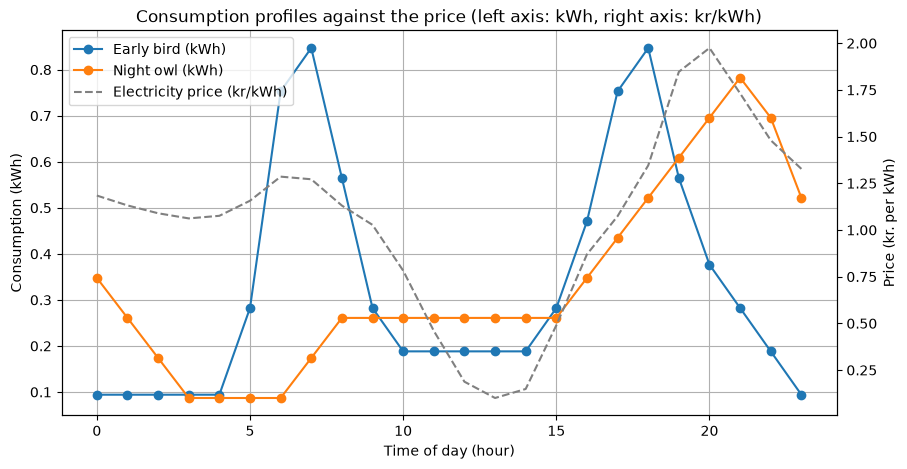

In [9]:
# Scalar multiplication: save 10% across the board
savings_profile = 0.9 * early_bird
print(f"10% less consumption: {savings_profile @ electricity_prices:.2f} kr. (before: {cost_early_bird:.2f} kr.)")

# Visualise the profiles against the price - two Y axes, since kWh and kr/kWh are not the same unit
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(hours, early_bird, 'o-', color='tab:blue', label="Early bird (kWh)")
ax1.plot(hours, night_owl, 'o-', color='tab:orange', label="Night owl (kWh)")
ax1.set_xlabel("Time of day (hour)")
ax1.set_ylabel("Consumption (kWh)")

ax2 = ax1.twinx()
ax2.plot(hours, electricity_prices, '--', color='gray', label="Electricity price (kr/kWh)")
ax2.set_ylabel("Price (kr. per kWh)")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

plt.title("Consumption profiles against the price (left axis: kWh, right axis: kr/kWh)")
ax1.grid(True)
plt.show()


#### Turn the dials

* **Your own profile**: Create a new cell (the `+ Code` button), copy in the lines with `early_bird = np.array([...])`, rename it to `my_profile`, and adjust the 24 numbers so they resemble your own day. Then calculate your daily bill: `print(my_profile @ electricity_prices)`.
* **Move 1 kWh**: In the `night_owl` vector, the number for 21:00 is the 22nd number in the row. Make it `0.5` smaller, make the number for 03:00 (the 4th number) `0.5` bigger, and run the cells again. How much does the night owl save by shifting consumption?


### To be continued
The case grows with the course: the next chapter unlocks after **Lesson 3** - A whole year through one multiplication